# Diabetes (Pima Indians): exploratory data analysis

768 adult women of Pima Indian heritage; 8 clinical measurements; outcome = diabetes diagnosed within five years.

> Part of the MediAssist CDSS project. Data loading and cleaning live in `ml/src/medml/data.py`, so this notebook and the training pipeline see exactly the same data.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from medml.data import load

sns.set_theme(style="whitegrid", palette="crest")
pd.set_option("display.precision", 2)

In [2]:
data = load("diabetes")
df = data.X.assign(target=data.y)
print(data.source)
print(df.shape)
df.head()

Pima Indians Diabetes Database (NIDDK; Smith et al., 1988)
(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,target
0,6,148.0,72.0,35.0,NaN,33.6,0.63,50,1
1,1,85.0,66.0,29.0,NaN,26.6,0.35,31,0
2,8,183.0,64.0,NaN,NaN,23.3,0.67,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.17,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.29,33,1


## Cleaning applied

In [3]:
for step in data.cleaning_log:
    print("-", step)

- Glucose: 5 zero values (0.7%) treated as missing
- BloodPressure: 35 zero values (4.6%) treated as missing
- SkinThickness: 227 zero values (29.6%) treated as missing
- Insulin: 374 zero values (48.7%) treated as missing
- BMI: 11 zero values (1.4%) treated as missing
- Missing values are imputed with the training-fold median inside the pipeline


## Summary statistics

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.85,3.37,0.00,1.00,3.00,6.00,17.00
Glucose,763.0,121.69,30.54,44.00,99.00,117.00,141.00,199.00
BloodPressure,733.0,72.41,12.38,24.00,64.00,72.00,80.00,122.00
SkinThickness,541.0,29.15,10.48,7.00,22.00,29.00,36.00,99.00
Insulin,394.0,155.55,118.78,14.00,76.25,125.00,190.00,846.00
BMI,757.0,32.46,6.92,18.20,27.50,32.30,36.60,67.10
DiabetesPedigreeFunction,768.0,0.47,0.33,0.08,0.24,0.37,0.63,2.42
Age,768.0,33.24,11.76,21.00,24.00,29.00,41.00,81.00
target,768.0,0.35,0.48,0.00,0.00,0.00,1.00,1.00


## Class balance and missing values

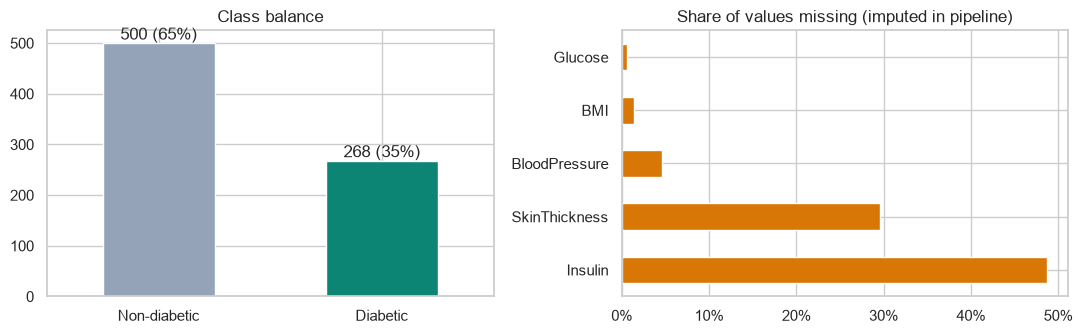

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
balance = pd.Series(data.class_balance())
balance.plot.bar(ax=axes[0], color=["#94a3b8", "#0d8574"], rot=0)
axes[0].set_title("Class balance")
for i, v in enumerate(balance):
    axes[0].text(i, v, f"{v} ({v / balance.sum():.0%})", ha="center", va="bottom")
missing = data.X.isna().mean().sort_values(ascending=False)
missing[missing > 0].plot.barh(ax=axes[1], color="#d97706")
axes[1].set_title("Share of values missing (imputed in pipeline)")
axes[1].xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
plt.tight_layout()

## Feature distributions by outcome

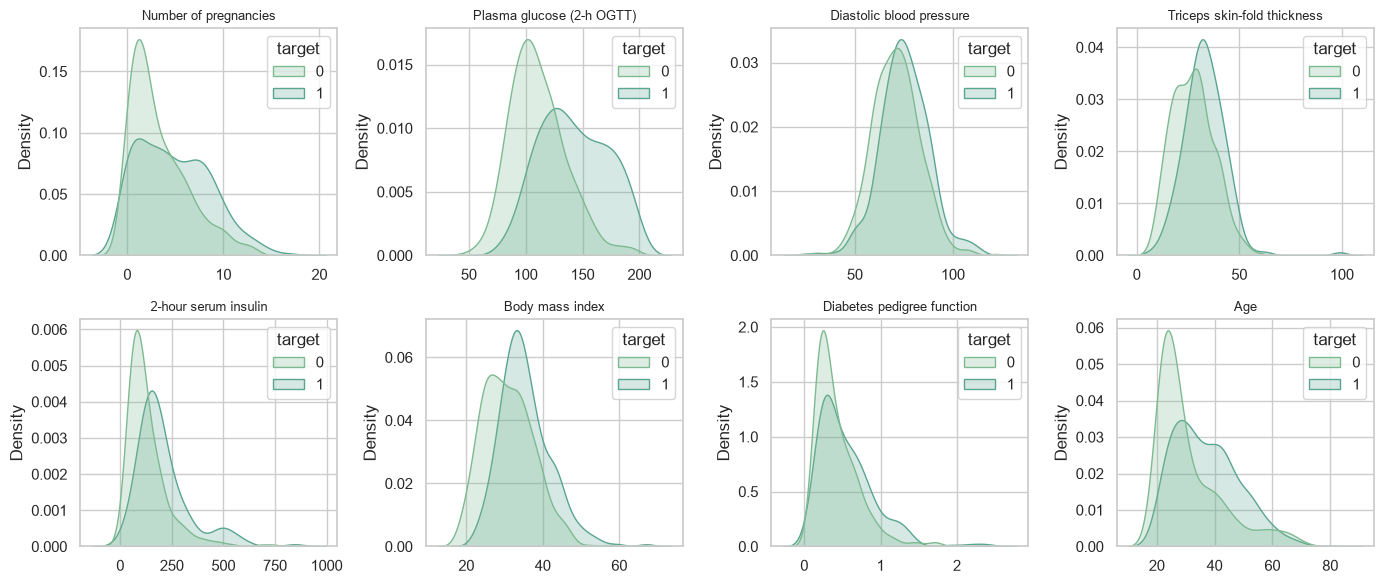

In [6]:
numeric = [f.name for f in data.features if f.kind == "numeric"]
labels = {f.name: f.label for f in data.features}
cols = 4
rows = int(np.ceil(len(numeric) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(14, 3 * rows))
for ax, col in zip(axes.flat, numeric):
    sns.kdeplot(
        data=df, x=col, hue="target", common_norm=False, fill=True, ax=ax, warn_singular=False
    )
    ax.set_title(labels[col], fontsize=9)
    ax.set_xlabel("")
for ax in list(axes.flat)[len(numeric) :]:
    ax.remove()
plt.tight_layout()

## Correlation with the outcome

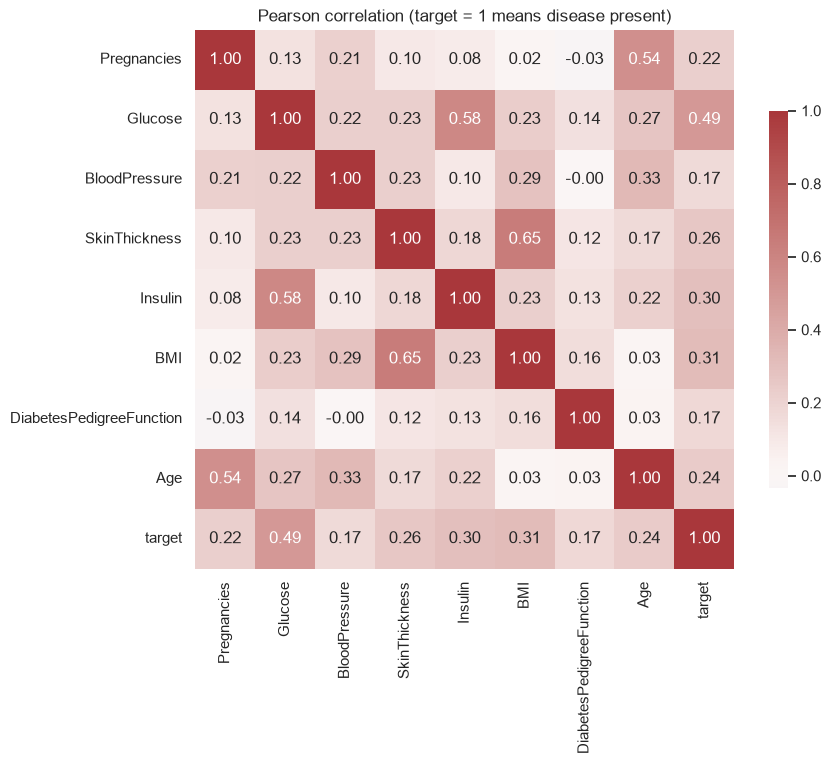

Glucose                     0.49
BMI                         0.31
Insulin                     0.30
SkinThickness               0.26
Age                         0.24
Pregnancies                 0.22
DiabetesPedigreeFunction    0.17
BloodPressure               0.17
Name: target, dtype: float64

In [7]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(9, 7))
sns.heatmap(
    corr, annot=True, fmt=".2f", cmap="vlag", center=0, square=True, cbar_kws={"shrink": 0.7}
)
plt.title("Pearson correlation (target = 1 means disease present)")
plt.show()
corr["target"].drop("target").sort_values(key=abs, ascending=False)

## Observations

- **Hidden missing values:** zeros in Insulin (49%) and SkinThickness (30%) are placeholders, not measurements. Treating them as real zeros would teach the model nonsense, so they are converted to missing and median-imputed inside the training folds.
- **Glucose is by far the strongest signal** (r = 0.49), followed by BMI (0.31) and, where measured, insulin (0.30) and skin thickness (0.26); age and pregnancies follow (~0.23). This matches clinical knowledge: OGTT glucose is a diagnostic criterion for diabetes.
- **Imbalance (65/35):** accuracy alone would be misleading; a model that always says 'non-diabetic' already scores 65%. We therefore select models on **F1** and report recall.